# Sequence 4 — circular path (`4_circle`)

Same structure and methods as the Sequence 1 notebook, adapted to a robot that drives a **circle** with a
**changing distance** to the camera:

| Step | Method (course week) | What changes for the circle |
|---|---|---|
| 0 | Rectification (Tim's calibration) | demo frame picked from the middle of the sequence |
| 1 | StereoBM disparity (Wk 3) | prints the depth range that `num_disp` can cover |
| 2 | Point cloud `.ply` (Wk 3 exercise) | wider top-down view |
| 3 | Background subtraction + morphology + connected components (Wk 1) | background built for **left and right**, so Step 8 gets an empty scene |
| 3b | Template matching (Wk 3) — comparison | template cut automatically from the detection; shows it fails as the robot turns |
| 4 | 3D position from median disparity + `Q` | Z is expected to vary |
| 5 | Kalman filter, constant velocity (Wk 7, Ex. 2c/2d) | **circle check** replaces the constant-speed/constant-distance check |
| 6 | Occlusion bridging (prediction only) | gap placed automatically on the curve |
| 7 | Video | same layout |
| 8 | 3D map | empty scene from the background pair |

**Run order:** top to bottom. Steps 4 and 7 loop over all 650 frames (a couple of minutes each).
The notebook must sit in the repo root (next to `stereo.py`), with the data in `part4/4_circle/left|right`.

## Step 0 — Load and rectify

650 left, 650 right


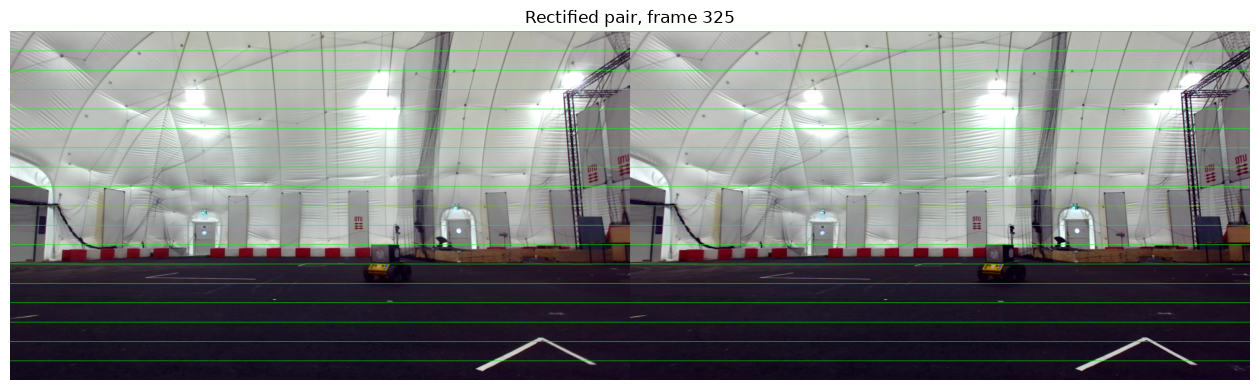

In [1]:
import os, glob
import cv2
import numpy as np
from matplotlib import pyplot as plt
from stereo import load_rectification, rectify

SEQ  = "4_circle"
DATA = f"part4/{SEQ}"                      # part4/4_circle/left and /right
OUT  = "seq4_outputs"                      # all saved files (.ply, .mp4) go here
os.makedirs(OUT, exist_ok=True)

lefts  = sorted(glob.glob(f"{DATA}/left/*.png"))
rights = sorted(glob.glob(f"{DATA}/right/*.png"))
assert [os.path.basename(p) for p in lefts] == [os.path.basename(p) for p in rights], "left/right frames do not match"
print(len(lefts), "left,", len(rights), "right")

# Calibration from Tim's notebook (default path: results/stereo_calib.npz)
#mtL and mtxR are intrinsic matrices for each camera (focal length and principal point)
mapL, mapR, Q = load_rectification()

def load_pair(i):
    """Read and rectify stereo pair number i."""
    return rectify(cv2.imread(lefts[i]), cv2.imread(rights[i]), mapL, mapR)

# Demo frame: the middle of the sequence (the robot is visible there)
DEMO = len(lefts) // 2
rectL, rectR = load_pair(DEMO)

# After rectification, the same point must lie on the same row in both images
both = np.hstack((rectL, rectR))
for y in range(0, both.shape[0], 40):
    cv2.line(both, (0, y), (both.shape[1], y), (0, 255, 0), 1)
plt.figure(figsize=(16, 5))
plt.imshow(both[..., ::-1])
plt.title(f"Rectified pair, frame {DEMO}")
plt.axis("off")
plt.show()

## Step 1 — Disparity with StereoBM (Week 3)

`num_disp` sets the largest disparity, and so the **closest** depth that can be measured: Z_min = f·B / num_disp.
Because the distance changes on the circle, check that the robot's closest approach is above Z_min.

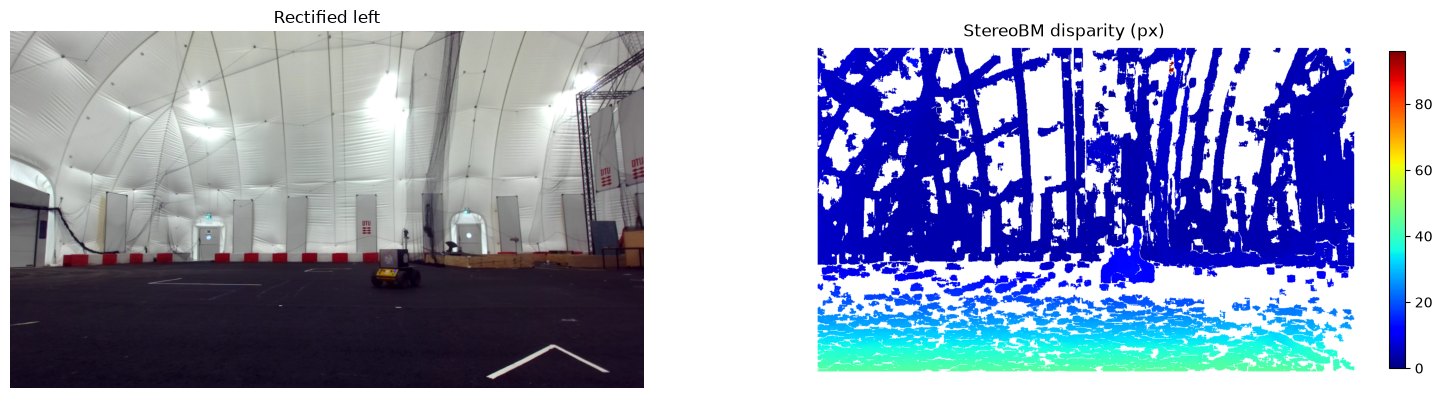

f = 628.1 px, baseline = 119.4 mm
num_disp = 96 px  ->  closest measurable depth Z_min = f*B/num_disp = 0.78 m
1 px of disparity at 10 m = 7.5 px   (far away, disparity gets small and depth gets noisy)


In [2]:
gray_left  = cv2.cvtColor(rectL, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(rectR, cv2.COLOR_BGR2GRAY)

min_disp   = 0
num_disp   = 6 * 16      # must be a multiple of 16
block_size = 15          # must be odd
stereo = cv2.StereoBM_create(numDisparities=num_disp, blockSize=block_size)
stereo.setMinDisparity(min_disp)
stereo.setDisp12MaxDiff(1)
stereo.setUniquenessRatio(10)
stereo.setSpeckleRange(2)
stereo.setSpeckleWindowSize(100)

def disparity(rL, rR):
    """StereoBM on a rectified pair. StereoBM returns disparity * 16."""
    return stereo.compute(cv2.cvtColor(rL, cv2.COLOR_BGR2GRAY),
                          cv2.cvtColor(rR, cv2.COLOR_BGR2GRAY)).astype(np.float32) / 16.0

disp = disparity(rectL, rectR)

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(rectL[..., ::-1]); 
ax[0].set_title("Rectified left"); 
ax[0].axis("off")
im = ax[1].imshow(np.where(disp > 0, disp, np.nan), cmap="jet", vmin=0, vmax=num_disp)
ax[1].set_title("StereoBM disparity (px)"); 
ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.025)
plt.show()

f_px = Q[2, 3]          # focal length in pixels
B_mm = 1.0 / Q[3, 2]    # baseline in mm
print(f"f = {f_px:.1f} px, baseline = {B_mm:.1f} mm")
print(f"num_disp = {num_disp} px  ->  closest measurable depth Z_min = f*B/num_disp = {f_px*B_mm/num_disp/1000:.2f} m")
print(f"1 px of disparity at 10 m = {f_px*B_mm/10000:.1f} px   (far away, disparity gets small and depth gets noisy)")

## Step 2 — 3D reconstruction of the scene (point cloud)

seq4_outputs/seq4_frame325.ply saved with 515995 points


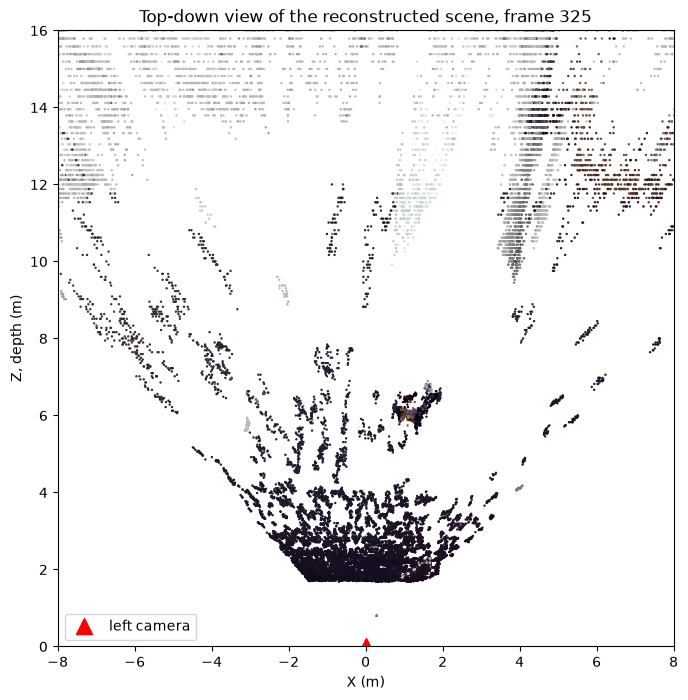

In [ ]:
def export_pointcloud(disparity_map, colors, Q, filename):
    """Reproject a disparity map to 3D with Q and save it as a coloured .ply (as in the block-matching exercise)."""
    # PLY header: tells MeshLab the file is ascii text, how many points there are, and what columns each point line has
    # %(vert_num)d is a placeholder that is filled with the real point count further down
    ply_header = """ply
format ascii 1.0
element vertex %(vert_num)d
property float x
property float y
property float z
property uchar red
property uchar green
property uchar blue
end_header
"""
    # Q = disparity-to-depth matrix from stereoRectify.
    # Input: disparity_map (H x W, disparity per left pixel) and Q (4x4).
    # Output: H x W x 3 array, the 3D point (X, Y, Z) of every left pixel in the rectified left camera frame.
    points = cv2.reprojectImageTo3D(disparity_map, Q)   # X, Y, Z in mm (Y points down)

    # keep only valid disparities and a sensible depth range (0.5 m to 30 m)
    # points[..., 2] = Z (index 2 of x, y, z), i.e. the depth of each pixel, H x W
    # the result is a boolean H x W mask (True = keep this pixel); & combines the three conditions
    mask = (disparity_map > 0) & (points[..., 2] > 500) & (points[..., 2] < 30000)
    out_points = points[mask]    # boolean indexing: H x W x 3 -> N x 3, only the kept points
    out_colors = colors[mask]    # same mask on the colour image: H x W x 3 -> N x 3 (r, g, b), so each point keeps its colour

    # flip Y and Z so the cloud is upright in MeshLab (same idea as the flip in the ICP exercise)
    # camera frame: Y down, Z forward. MeshLab: Y up, Z towards viewer. Multiplying each column by [1, -1, -1] fixes that
    out_points = out_points * np.array([1, -1, -1])

    verts = np.hstack([out_points, out_colors])    # glue side by side: N x 3 and N x 3 -> N x 6 (x, y, z, r, g, b)
    with open(filename, "wb") as fh:    # open the output file for writing bytes ("wb"), fh is the file handle
        fh.write((ply_header % dict(vert_num=len(verts))).encode("utf-8"))   # insert the point count into the header, convert text to bytes, write it
        np.savetxt(fh, verts, fmt="%f %f %f %d %d %d")   # write one text line per point; floats for x y z, integers for r g b
    print(f"{filename} saved with {len(verts)} points")
    return points, mask    # full 3D array and mask are returned so they can be reused for the plot below


colors_rgb = cv2.cvtColor(rectL, cv2.COLOR_BGR2RGB)   # OpenCV images are BGR; swap channels to RGB for PLY and matplotlib. rectL = rectified left image
# disp = disparity map on the left image grid, Q = from stereoRectify, last argument = output file path
# returns the 3D points (H x W x 3) and the validity mask (H x W)
points, mask = export_pointcloud(disp, colors_rgb, Q, f"{OUT}/seq4_frame{DEMO}.ply")

# Top-down view of the scene (X vs depth Z), useful as a figure for the report
pts = points[mask]              # N x 3 valid points (not flipped, so Z is positive depth)
col = colors_rgb[mask] / 255    # N x 3 colours scaled to 0-1, which is what matplotlib expects
# pick up to 60000 random point indices (no repeats, fixed seed 0 so it is reproducible); plotting millions of points is too slow
sub = np.random.default_rng(0).choice(len(pts), min(60000, len(pts)), replace=False)
plt.figure(figsize=(8, 8))      # new square figure, 8 x 8 inches
# scatter(x values, y values, c = colour per point, s = marker size); mm -> m by dividing by 1000
# x axis = X (sideways), y axis = Z (depth); Y (height) is dropped, which gives the bird's-eye view
plt.scatter(pts[sub, 0] / 1000, pts[sub, 2] / 1000, c=col[sub], s=0.5)
plt.plot(0, 0, "r^", ms=12, label="left camera")   # red triangle ("r^") of size 12 at the origin = left camera position
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)")
plt.title(f"Top-down view of the reconstructed scene, frame {DEMO}")
# xlim/ylim = visible range in m; set_aspect("equal") makes 1 m look the same on both axes; legend() shows the camera label
plt.xlim(-8, 8); plt.ylim(0, 16); plt.gca().set_aspect("equal"); plt.legend()
plt.show()   # display the figure

#60,000 random points

## Step 3 — Detection by background subtraction (Image Processing lecture)

The camera is static and the robot keeps moving around the circle, so the **per-pixel median over time**
is the empty hall. The robot is whatever differs from it. The background is built for both cameras: the left one
is used for detection, and the pair gives an empty-scene point cloud in Step 8.

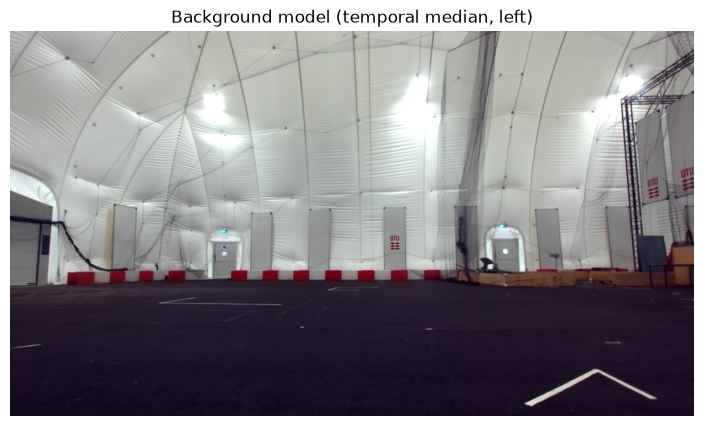

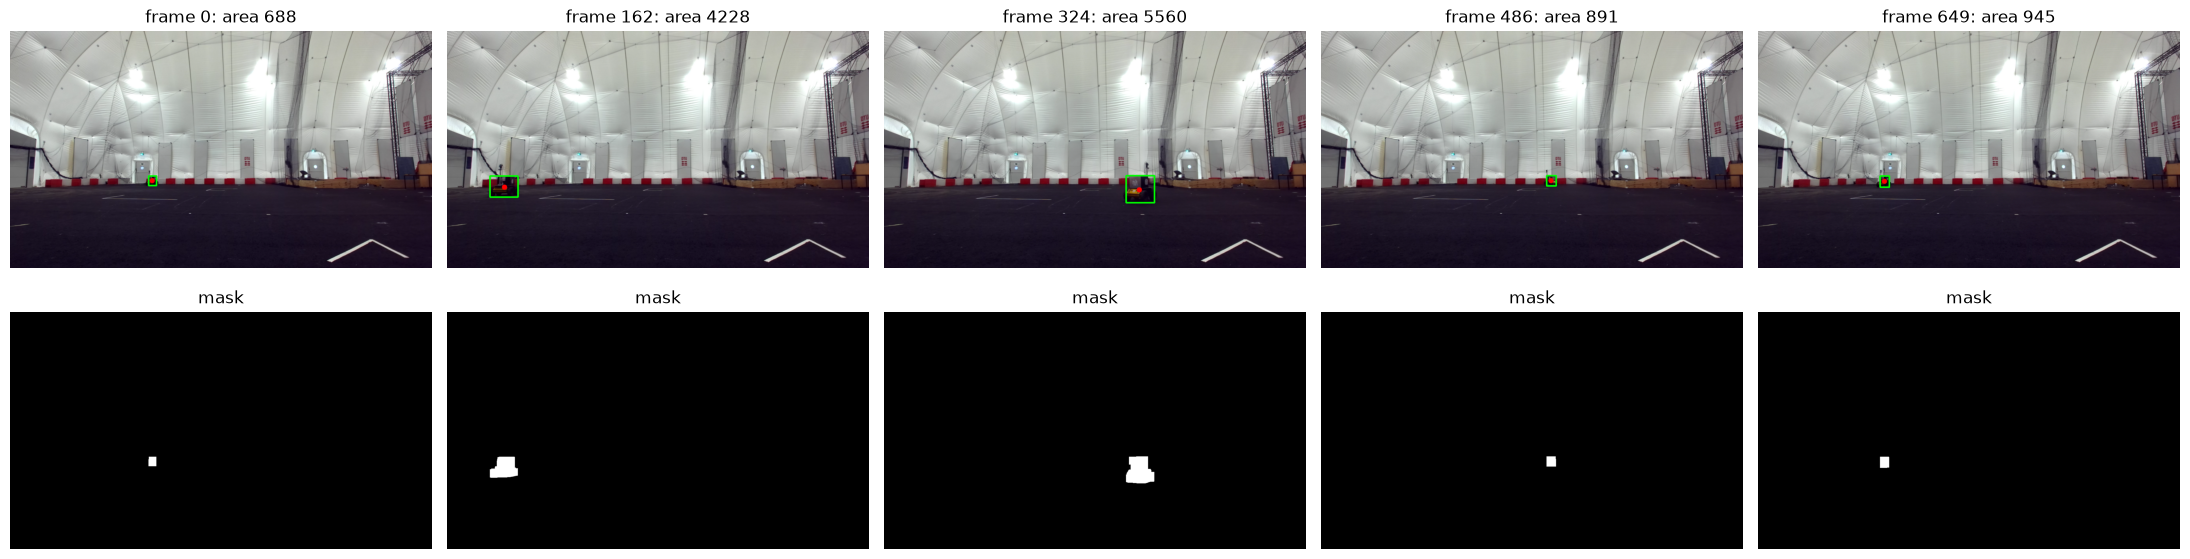

In [ ]:
# 1. Background model: per-pixel MEDIAN over ~N_BG frames spread over the whole sequence.
#    The robot covers each pixel for only a few of them, so the median is the empty hall.
N_BG = 50
#take 50 frames that are evenly spaced out
bg_idx = np.linspace(0, len(lefts) - 1, N_BG).astype(int)
bg_L, bg_R = [], []
for i in bg_idx:
    #load pair loads left and right and rectified with Map_L and map_R
    l, r = load_pair(i)
    bg_L.append(l); 
    bg_R.append(r)
    #store mediam value of pixels across all L and right
background   = np.median(np.array(bg_L), axis=0).astype(np.uint8); del bg_L
background_R = np.median(np.array(bg_R), axis=0).astype(np.uint8); del bg_R

plt.figure(figsize=(10, 5))
plt.imshow(background[..., ::-1]); plt.title("Background model (temporal median, left)"); plt.axis("off")
plt.show()

# 2. Parameters (check them on the test frames below; the robot is smaller when it is far away)
DIFF_THR = 25      # grey-level difference that counts as "changed" pixel value
MIN_AREA = 400     # smallest blob (px) that can be the robot
#if less 400 pixel area change -> considered speks or noise

K_OPEN  = np.ones((3, 3), np.uint8)                              # removes single noisy pixels
K_CLOSE = np.ones((15, 15), np.uint8)                            # fills holes inside the dark robot body
K_MAST  = cv2.getStructuringElement(cv2.MORPH_RECT, (21, 21))    # removes the thin mast on top


def foreground_mask(img):
    """Difference to background -> threshold -> morphology (Image Processing lecture)."""
    #computes diff bet frames vs background per channel and per pixel
    #axis=2 takes largest change across 3 cahnnels
    diff = cv2.absdiff(img, background).max(axis=2)          # largest change over the 3 colour channels
    #thresholding if pixels change more than 25 it is considered TRUE
    mask = (diff > DIFF_THR).astype(np.uint8) * 255          # thresholding ouput 1 or 0
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  K_OPEN)   # opening: remove noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, K_CLOSE)  # closing: fill holes
    #trim thin parts
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  K_MAST)   # opening: remove the mast
    return mask


def detect(img):
    """Connected components: the robot is the largest blob. Returns None if there is no robot."""
    mask = foreground_mask(img)
    #mask is black image with white blobs
    #connected components with stats returns number of blobs labelled by number, stats [x,y,width,height,area] and cents (centrids)
    n, labels, stats, cents = cv2.connectedComponentsWithStats(mask)
    #only 1 label would be background (as it is labelled)
    if n < 2:
        return None
    #returns label of largest blob without considering background. 1 + converts it back to original label
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])     # label 0 is the background
    x, y, w, h, area = stats[k]
    if area < MIN_AREA:
        return None
    return {"bbox": (x, y, w, h), "centroid": cents[k], "area": area,
            "mask": labels == k, "border": x <= 1 or x + w >= img.shape[1] - 1}


# 3. Test on frames spread around the circle (near and far positions)
test_frames = np.linspace(0, len(lefts) - 1, 5).astype(int)
fig, ax = plt.subplots(2, len(test_frames), figsize=(22, 6))
for j, i in enumerate(test_frames):
    img = load_pair(i)[0]
    det = detect(img)
    vis = img.copy()
    title = f"frame {i}: no robot"
    if det: #if robot found
        x, y, w, h = det["bbox"]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 4)
        cv2.circle(vis, tuple(int(c) for c in det["centroid"]), 8, (0, 0, 255), -1)
        title = f"frame {i}: area {det['area']}" + (" (border)" if det["border"] else "")
    ax[0, j].imshow(vis[..., ::-1]); ax[0, j].set_title(title)
    ax[1, j].imshow(foreground_mask(img), cmap="gray"); ax[1, j].set_title("mask")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout()
plt.show()

## Step 3b — Comparison: template matching (Week 3)

The template is cut from the background-subtraction detection in the demo frame. On a circle the robot
**rotates** and **changes size**, so a fixed template stops matching. The distance to the
background-subtraction centroid shows where it fails. This is the argument for background subtraction in the report.

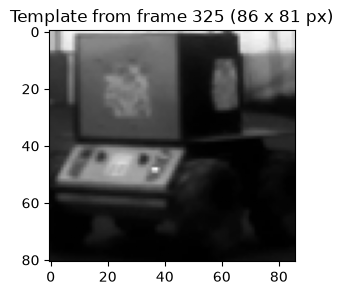

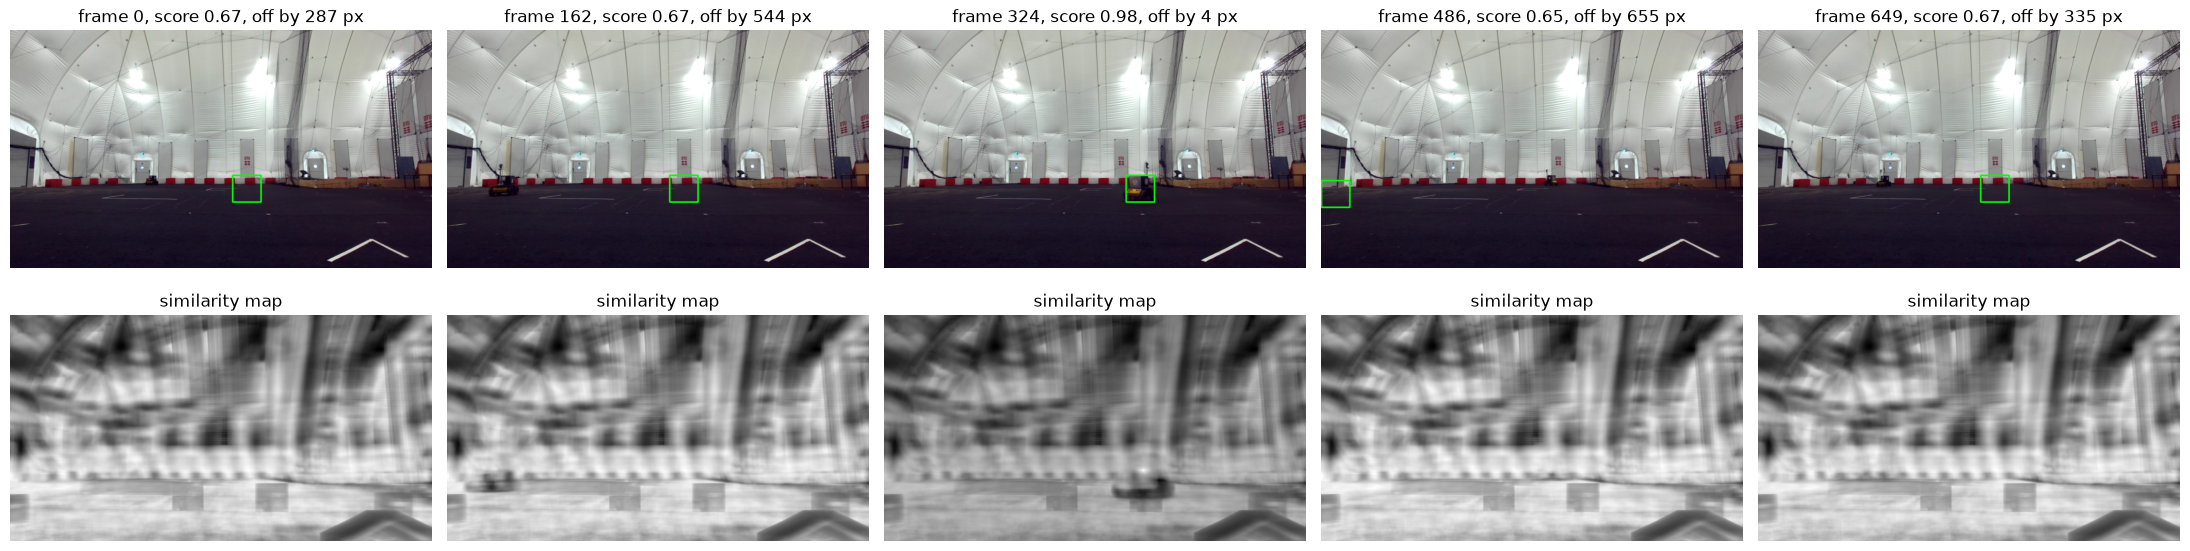

In [5]:
# 1. Template: the robot body in a frame where it is detected (closest to the demo frame)
cand = sorted(range(len(lefts)), key=lambda i: abs(i - DEMO))
for t_frame in cand[:60]:
    t_img = load_pair(t_frame)[0]
    t_det = detect(t_img)
    if t_det and not t_det["border"]:
        break
x0, y0, tw, th = t_det["bbox"]
template = cv2.cvtColor(t_img, cv2.COLOR_BGR2GRAY)[y0:y0 + th, x0:x0 + tw]

plt.figure(figsize=(4, 3))
plt.imshow(template, cmap="gray")
plt.title(f"Template from frame {t_frame} ({tw} x {th} px)")
plt.show()


def match_robot(gray, template):
    """Template matching as in the exercise. Returns score map, best score and box (x, y, w, h)."""
    res = cv2.matchTemplate(gray, template, cv2.TM_CCOEFF_NORMED)
    _, max_val, _, max_loc = cv2.minMaxLoc(res)
    return res, max_val, (max_loc[0], max_loc[1], template.shape[1], template.shape[0])


# 2. Test on the same frames as Step 3, and compare with background subtraction
fig, ax = plt.subplots(2, len(test_frames), figsize=(22, 6))
for j, i in enumerate(test_frames):
    img = load_pair(i)[0]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    res, score, (x, y, w, h) = match_robot(gray, template)
    det = detect(img)
    if det:
        err = np.hypot(x + w / 2 - det["centroid"][0], y + h / 2 - det["centroid"][1])
        txt = f"score {score:.2f}, off by {err:.0f} px"
    else:
        txt = f"score {score:.2f} (no robot)"
    vis = cv2.rectangle(img.copy(), (x, y), (x + w, y + h), (0, 255, 0), 4)
    ax[0, j].imshow(vis[..., ::-1]); ax[0, j].set_title(f"frame {i}, {txt}")
    ax[1, j].imshow(res, cmap="gray"); ax[1, j].set_title("similarity map")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout()
plt.show()

## Step 4 — 3D position of the robot in every frame

robot detected in 646 of 650 frames
3D position in    646 frames


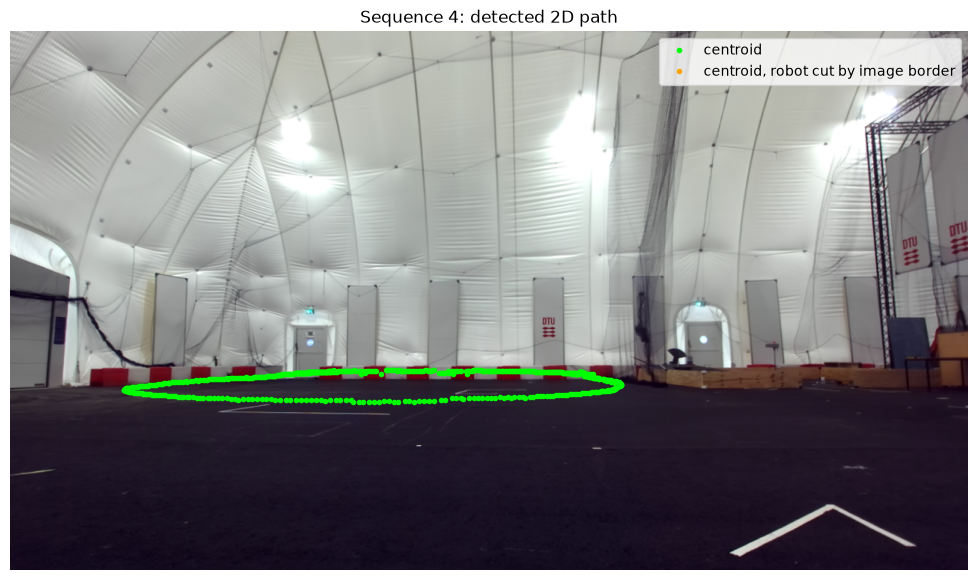

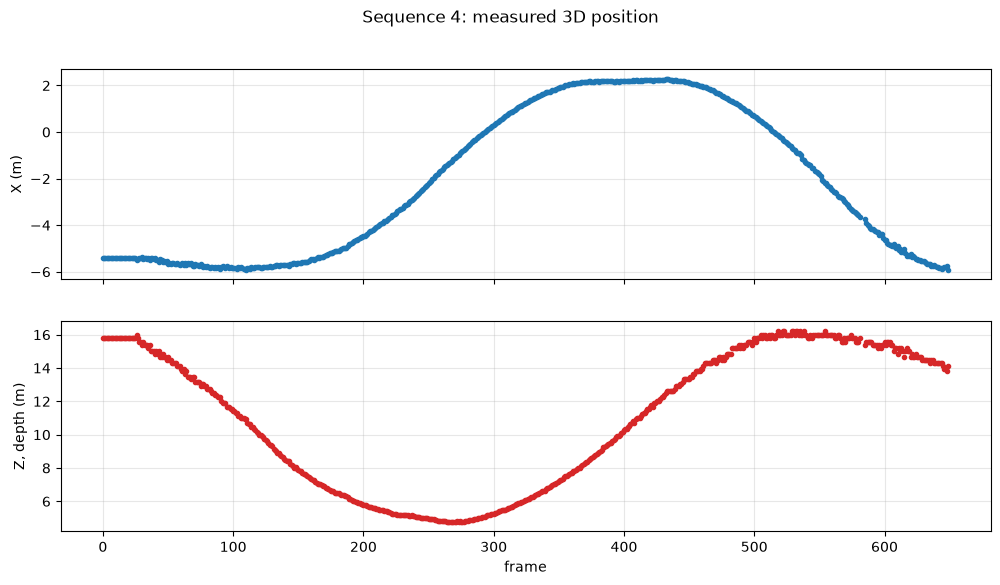

In [9]:
# Valid-disparity requirement scales with the blob: far away the robot is small, so a fixed
# count (Sequence 1 used 200 px at ~4 m) would reject most far-side frames on the circle.

#AT least 10 percent of robots blob pixel must have a valid disparity
MIN_VALID_FRAC = 0.10   # at least 10 % of the robot's pixels must have a valid disparity
#At least 30 pixels must have this valid disparity
MIN_VALID_ABS  = 30     # and never fewer than 30 pixels


#input det is dictionary from detect, disp is the disparity map
def locate_3d(det, disp):
    """3D position (mm) of a detection: mask centroid + median disparity inside the mask."""
    #outputs the disparity for the pixels were the robot was detected in the mask
    d = disp[det["mask"]]
    #take only valid disparities
    d = d[d > 0]                       # only valid disparities
    #this conditon scaled, we need the number of valid dispairty pixels to be at least 30 pixels
    #or 10 percent of the area \
    if d.size < max(MIN_VALID_ABS, MIN_VALID_FRAC * det["area"]):
        return None, np.nan
    #take median disparity
    d_med = float(np.median(d))
    #centroid coordinates from the blob
    u, v = det["centroid"]
    #same this as cv2.repojectImageto3D but done for a single pixel
    X, Y, Z, W = Q @ np.array([u, v, d_med, 1.0])   # same as reprojectImageTo3D, for one pixel
    return np.array([X, Y, Z]) / W, d_med
#at the centroid of the blob, it uses the median disparity to compute its depth
#you get the center of the object tracked in 3D


# Run over the whole sequence (takes a couple of minutes for 650 frames)
results = []
for i in range(len(lefts)):
    rL, rR = load_pair(i)
    #background substraction on left image
    det = detect(rL)
    p3d, d_med = None, np.nan
    if det:
        p3d, d_med = locate_3d(det, disparity(rL, rR))
    results.append({
        "frame": i,
        "detected": det is not None,
        "border": det["border"] if det else False,
        "bbox": det["bbox"] if det else None,
        "uv": det["centroid"] if det else np.array([np.nan, np.nan]),
        "disp": d_med,
        "xyz": p3d if p3d is not None else np.array([np.nan] * 3),
    })

frames = np.array([r["frame"] for r in results])
uv     = np.array([r["uv"] for r in results])
xyz    = np.array([r["xyz"] for r in results]) / 1000      # metres
border = np.array([r["border"] for r in results])
det_frames = frames[[r["detected"] for r in results]]
xyz_frames = frames[~np.isnan(xyz[:, 2])]
print(f"robot detected in {len(det_frames)} of {len(frames)} frames")
print(f"3D position in    {len(xyz_frames)} frames")
if len(xyz_frames) < 0.5 * max(1, len(det_frames)):
    print("-> many detections have no valid disparity: lower MIN_VALID_FRAC, or lower block_size in Step 1")

# Plot 1: 2D path of the centroid on the background image
plt.figure(figsize=(14, 7))
plt.imshow(background[..., ::-1])
plt.plot(uv[~border, 0], uv[~border, 1], "o", ms=3, color="lime", label="centroid")
plt.plot(uv[border, 0], uv[border, 1], "o", ms=3, color="orange", label="centroid, robot cut by image border")
plt.legend(); plt.axis("off"); plt.title("Sequence 4: detected 2D path")
plt.show()

# Plot 2: X and Z over time (on a circle both oscillate)
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(frames, xyz[:, 0], ".", color="tab:blue"); ax[0].set_ylabel("X (m)"); ax[0].grid(alpha=0.3)
ax[1].plot(frames, xyz[:, 2], ".", color="tab:red");  ax[1].set_ylabel("Z, depth (m)"); ax[1].grid(alpha=0.3)
ax[1].set_xlabel("frame"); fig.suptitle("Sequence 4: measured 3D position")
plt.show()

## Step 5 — Tracking with a Kalman filter in 2D and 3D (Week 7)

Same filter as Sequence 1: the functions from Exercise 2c, a **constant-velocity** model per axis, and process noise
from a small random acceleration `q`. On a circle the robot accelerates towards the centre (a = v²/r), so `q` must be
at least that large; Step 5b checks it.

F for 2D (same as Exercise 2d):
 [[1. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 1.]
 [0. 0. 0. 1.]]
H for 2D (same as Exercise 2d):
 [[1. 0. 0. 0.]
 [0. 0. 1. 0.]]


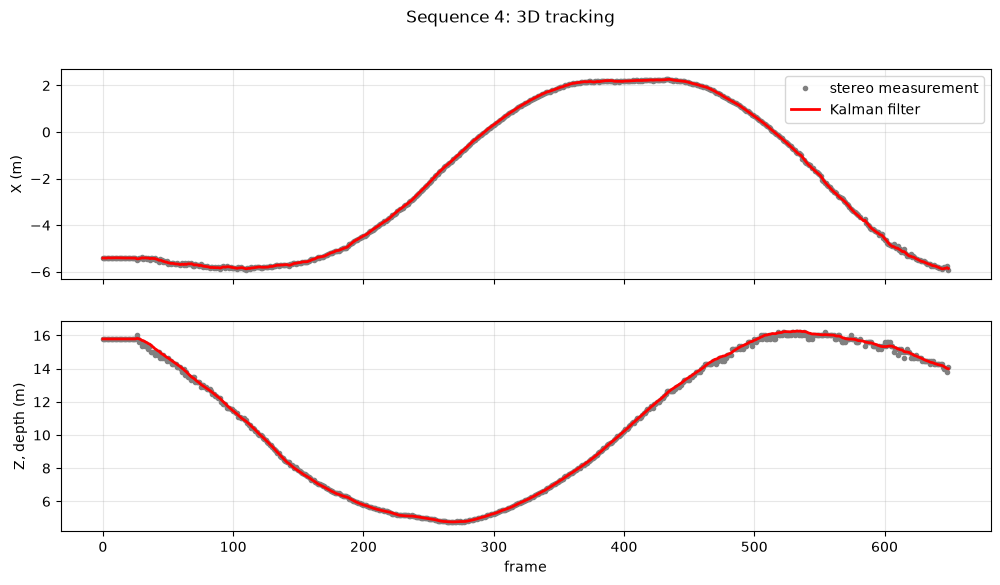

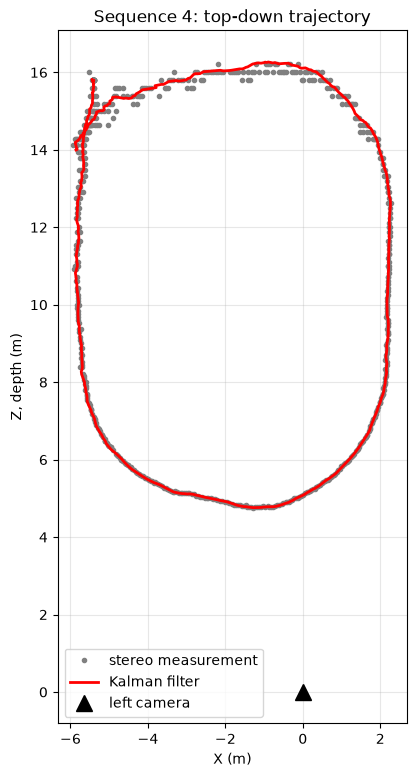

In [10]:
# --- Kalman functions from Exercise 2c (week 7), with process noise Q added to predict ---
def update(x, P, Z, H, R):
    #Z is measuremnt
    y = Z - np.dot(H, x)                            # innovation
    S = np.dot(H, np.dot(P, H.T)) + R               # innovation covariance
    K = np.dot(P, np.dot(H.T, np.linalg.pinv(S)))   # Kalman gain
    x = x + np.dot(K, y)                            # state update
    I = np.eye(P.shape[0])
    P = np.dot((I - np.dot(K, H)), P)               # covariance update
    return [x, P]


def predict(x, P, F, u, Q):
    x = np.dot(F, x) + u                            # predict next state
    P = np.dot(F, np.dot(P, F.T)) + Q               # added: + Q (process noise), as in the lecture
    return [x, P]


def make_matrices(dim, q):
    """F, H, Q for a constant-velocity model, state ordered as in Exercise 2d:
    [pos_1, vel_1, pos_2, vel_2, ...]. One 2x2 block per axis."""
    F1 = np.array([[1, 1], [0, 1]])                       # 1D model from Exercise 2c
    H1 = np.array([[1, 0]])
    Q1 = np.array([[0.25, 0.5], [0.5, 1.0]]) * q**2       # small random acceleration per frame
    F = np.kron(np.eye(dim), F1)                          # block-diagonal, like F in Exercise 2d
    H = np.kron(np.eye(dim), H1)
    Q = np.kron(np.eye(dim), Q1)
    return F, H, Q


Q_PX = 0.5     # random acceleration, 2D (px / frame^2)
Q_MM = 5.0     # random acceleration, 3D (mm / frame^2)  -> checked against v^2/r in Step 5b
F2, H2, Q2 = make_matrices(2, q=Q_PX)    # 2D: pixels
F3, H3, Q3 = make_matrices(3, q=Q_MM)    # 3D: millimetres
print("F for 2D (same as Exercise 2d):\n", F2)
print("H for 2D (same as Exercise 2d):\n", H2)

# --- Measurement noise R (f_px and B_mm come from the stereo Q matrix, Step 1) ---
SIGMA_PX = 3.0      # centroid noise (px)
SIGMA_D  = 0.25     # disparity noise (px)
BORDER   = 25.0     # robot cut by the image border -> trust it 25x less


def R_2d(border):
    return np.eye(2) * SIGMA_PX**2 * (BORDER if border else 1)


def R_3d(p, border):
    Z = p[2]
    s_z  = Z**2 / (f_px * B_mm) * SIGMA_D    # depth error grows with Z^2 (from Z = f*B/d)
    s_xy = SIGMA_PX * Z / f_px
    return np.diag([s_xy**2, s_xy**2, s_z**2]) * (BORDER if border else 1)


def start_state(z, R0, vel_var):
    """Initial x and P: position = first measurement, velocity = 0 but very uncertain."""
    dim = len(z)
    x = np.zeros((2 * dim, 1))
    x[0::2, 0] = z                      # positions at indices 0, 2, (4)
    P = np.eye(2 * dim) * vel_var       # large variance for the velocities
    P[0::2, 0::2] = R0                  # position variance = measurement variance
    return x, P


# --- Run the filters over the whole sequence ---
MAX_MISSES = 15     # stop a track after this many frames without a measurement
n = len(results)
kf_uv  = np.full((n, 2), np.nan)
kf_xyz = np.full((n, 3), np.nan)
kf_vel = np.full((n, 3), np.nan)
x2 = P2 = x3 = P3 = None
miss2 = miss3 = 0

for k, r in enumerate(results):
    # measurements of this frame (None = no measurement)
    z2 = r["uv"] if r["detected"] else None
    z3 = r["xyz"] if not np.isnan(r["xyz"][0]) else None

    # ---- 2D (pixels) ----
    if x2 is None and z2 is not None:
        x2, P2 = start_state(z2, R_2d(r["border"]), vel_var=30**2)
    elif x2 is not None:
        if z2 is not None:
            x2, P2 = update(x2, P2, z2.reshape(-1, 1), H2, R_2d(r["border"]))
            miss2 = 0
        else:
            miss2 += 1
    if x2 is not None:
        kf_uv[k] = x2[0::2, 0]                          # positions u, v
        x2, P2 = predict(x2, P2, F2, np.zeros_like(x2), Q2)
        u_next = x2[0, 0]
        left_view = u_next < 0 or u_next > rectL.shape[1]   # predicted outside the image
        if miss2 > MAX_MISSES or (left_view and z2 is None):
            x2, miss2 = None, 0
            x3, miss3 = None, 0

    # ---- 3D (mm) ----
    if x3 is None and z3 is not None:
        x3, P3 = start_state(z3, R_3d(z3, r["border"]), vel_var=200**2)
    elif x3 is not None:
        if z3 is not None:
            x3, P3 = update(x3, P3, z3.reshape(-1, 1), H3, R_3d(z3, r["border"]))
            miss3 = 0
        else:
            miss3 += 1
    if x3 is not None:
        kf_xyz[k] = x3[0::2, 0] / 1000                  # positions X, Y, Z in metres
        kf_vel[k] = x3[1::2, 0]                         # velocities in mm/frame
        x3, P3 = predict(x3, P3, F3, np.zeros_like(x3), Q3)
        if miss3 > MAX_MISSES:
            x3, miss3 = None, 0

# --- Plots ---
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a, j, name in [(ax[0], 0, "X (m)"), (ax[1], 2, "Z, depth (m)")]:
    a.plot(frames, xyz[:, j], ".", color="grey", label="stereo measurement")
    a.plot(frames, kf_xyz[:, j], "-", color="red", lw=2, label="Kalman filter")
    a.set_ylabel(name); a.grid(alpha=0.3)
ax[0].legend(); ax[1].set_xlabel("frame")
fig.suptitle("Sequence 4: 3D tracking")
plt.show()

plt.figure(figsize=(9, 9))
plt.plot(xyz[:, 0], xyz[:, 2], ".", color="grey", label="stereo measurement")
plt.plot(kf_xyz[:, 0], kf_xyz[:, 2], "-", color="red", lw=2, label="Kalman filter")
plt.plot(0, 0, "k^", ms=12, label="left camera")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)"); plt.gca().set_aspect("equal")
plt.grid(alpha=0.3); plt.legend()
plt.title("Sequence 4: top-down trajectory")
plt.show()

## Step 5b — Circle check (replaces Sequence 1's constant speed / constant distance check)

Fit a circle to the filtered top-down path (least squares on X, Z). Report the radius, how well the points fit it,
the speed, the depth range, and the centripetal acceleration v²/r compared with the filter's `q`.

circle centre: X = -1.93 m, Z = 10.68 m   radius = 5.25 m
fit residual (RMS): 617 mm
speed: 52.0 ± 15.5 mm/frame
depth range: 4.76 m to 16.27 m
centripetal acceleration v^2/r = 0.52 mm/frame^2  vs  q = 5.0 mm/frame^2 (ok: q covers it)


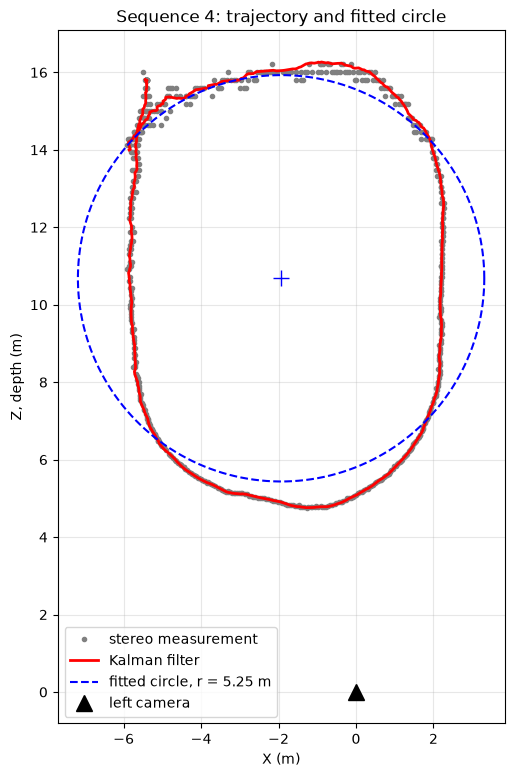

In [11]:
def fit_circle(x, z):
    """Algebraic least-squares circle fit: x^2 + z^2 = 2*a*x + 2*b*z + c."""
    A = np.c_[2 * x, 2 * z, np.ones_like(x)]
    a, b, c = np.linalg.lstsq(A, x**2 + z**2, rcond=None)[0]
    return a, b, np.sqrt(c + a**2 + b**2)


good = ~border & ~np.isnan(kf_xyz[:, 0])
circle_ok = good.sum() >= 10
assert circle_ok, "fewer than 10 tracked 3D points: fix detection (Step 3) or disparity (Steps 1, 4) first"
cx, cz, rad = fit_circle(kf_xyz[good, 0], kf_xyz[good, 2])
resid = np.hypot(kf_xyz[good, 0] - cx, kf_xyz[good, 2] - cz) - rad
speed = np.linalg.norm(kf_vel[good][:, [0, 2]], axis=1)          # mm/frame, in the ground plane
a_c = speed.mean()**2 / (rad * 1000)                              # v^2 / r in mm/frame^2

print(f"circle centre: X = {cx:+.2f} m, Z = {cz:.2f} m   radius = {rad:.2f} m")
print(f"fit residual (RMS): {np.sqrt(np.mean(resid**2))*1000:.0f} mm")
print(f"speed: {speed.mean():.1f} ± {speed.std():.1f} mm/frame")
print(f"depth range: {kf_xyz[good, 2].min():.2f} m to {kf_xyz[good, 2].max():.2f} m")
print(f"centripetal acceleration v^2/r = {a_c:.2f} mm/frame^2  vs  q = {Q_MM} mm/frame^2 "
      + ("(ok: q covers it)" if Q_MM >= a_c else "(increase Q_MM)"))

t = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(9, 9))
plt.plot(xyz[:, 0], xyz[:, 2], ".", color="grey", label="stereo measurement")
plt.plot(kf_xyz[:, 0], kf_xyz[:, 2], "-", color="red", lw=2, label="Kalman filter")
plt.plot(cx + rad * np.cos(t), cz + rad * np.sin(t), "b--", lw=1.5, label=f"fitted circle, r = {rad:.2f} m")
plt.plot(cx, cz, "b+", ms=12)
plt.plot(0, 0, "k^", ms=12, label="left camera")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)"); plt.gca().set_aspect("equal")
plt.grid(alpha=0.3); plt.legend(); plt.title("Sequence 4: trajectory and fitted circle")
plt.show()

## Step 6 — Bridging an occlusion (simulated)

Sequence 4 has no real occlusion, so, as in Sequence 1, the measurements of 30 frames are hidden and the filter
only predicts. The gap is placed in the middle of the tracked part. On a circle the constant-velocity prediction
continues in a **straight line** while the robot turns, so the error grows faster than in Sequence 1. That is a
point for the Discussion.

error during the 30-frame gap: mean 147 mm, at the end 370 mm
uncertainty in X: 18 mm before the gap -> 541 mm at its end


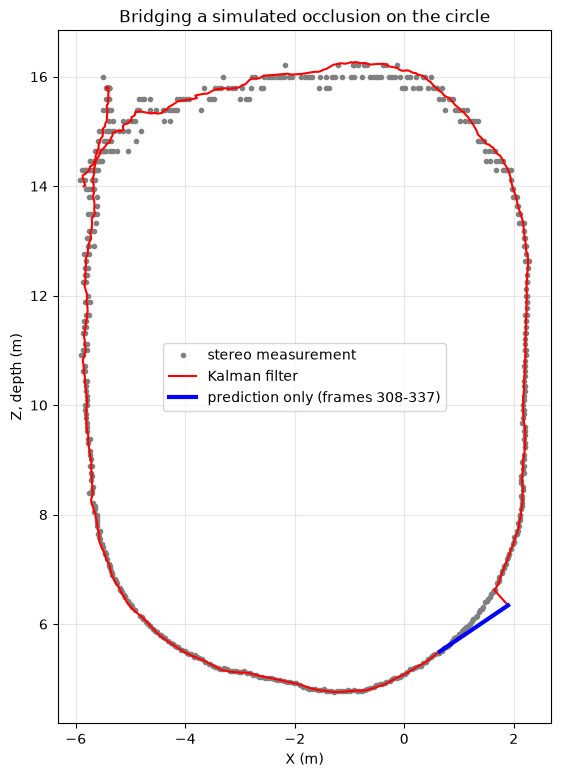

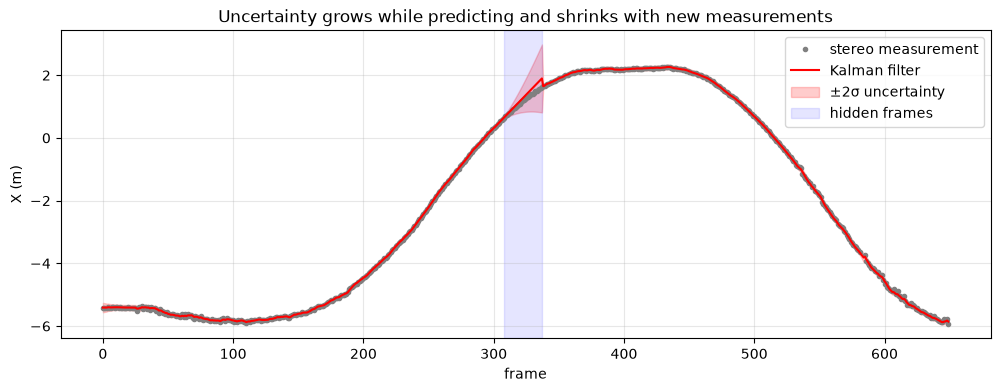

In [9]:
valid3d = np.where(~np.isnan(xyz[:, 2]))[0]
assert len(valid3d) > 40, "not enough 3D measurements to simulate a 30-frame gap"
mid = valid3d[len(valid3d) // 2]
GAP = range(mid - 15, mid + 15)          # frames where we pretend the robot is hidden

x = P = None
occ_xyz = np.full((n, 3), np.nan)
occ_std = np.full((n, 3), np.nan)

for k, r in enumerate(results):
    z3 = r["xyz"] if not np.isnan(r["xyz"][0]) else None
    if k in GAP:
        z3 = None                                    # hide the measurement

    if x is None:
        if z3 is not None:
            x, P = start_state(z3, R_3d(z3, r["border"]), vel_var=200**2)
        else:
            continue
    elif z3 is not None:
        x, P = update(x, P, z3.reshape(-1, 1), H3, R_3d(z3, r["border"]))

    occ_xyz[k] = x[0::2, 0] / 1000                   # estimate at this frame (m)
    occ_std[k] = np.sqrt(np.diag(P)[0::2]) / 1000    # its standard deviation (m)
    x, P = predict(x, P, F3, np.zeros_like(x), Q3)

# Error during the gap: predicted position vs the hidden stereo measurement
gap = np.array(list(GAP))
err = np.linalg.norm(occ_xyz[gap] - xyz[gap], axis=1) * 1000
print(f"error during the {len(gap)}-frame gap: mean {np.nanmean(err):.0f} mm, at the end {err[-1]:.0f} mm")
print(f"uncertainty in X: {occ_std[gap[0]-1, 0]*1000:.0f} mm before the gap -> {occ_std[gap[-1], 0]*1000:.0f} mm at its end")

# Plot 1: top-down view with the gap highlighted
plt.figure(figsize=(9, 9))
plt.plot(xyz[:, 0], xyz[:, 2], ".", color="grey", label="stereo measurement")
plt.plot(occ_xyz[:, 0], occ_xyz[:, 2], "r-", label="Kalman filter")
plt.plot(occ_xyz[gap, 0], occ_xyz[gap, 2], "b-", lw=3, label=f"prediction only (frames {gap[0]}-{gap[-1]})")
plt.xlabel("X (m)"); plt.ylabel("Z, depth (m)"); plt.gca().set_aspect("equal")
plt.legend(); plt.grid(alpha=0.3)
plt.title("Bridging a simulated occlusion on the circle")
plt.show()

# Plot 2: X over time with the uncertainty band
plt.figure(figsize=(12, 4))
plt.plot(frames, xyz[:, 0], ".", color="grey", label="stereo measurement")
plt.plot(frames, occ_xyz[:, 0], "r-", label="Kalman filter")
plt.fill_between(frames, occ_xyz[:, 0] - 2 * occ_std[:, 0], occ_xyz[:, 0] + 2 * occ_std[:, 0],
                 color="red", alpha=0.2, label="±2σ uncertainty")
plt.axvspan(gap[0], gap[-1], color="blue", alpha=0.1, label="hidden frames")
plt.xlabel("frame"); plt.ylabel("X (m)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Uncertainty grows while predicting and shrinks with new measurements")
plt.show()

## Step 7 — Video (detection, Kalman track and disparity side by side)

In [10]:
FPS = 15
SCALE = 0.5     # half resolution keeps the file small
H_img, W_img = rectL.shape[:2]
w_s, h_s = int(W_img * SCALE), int(H_img * SCALE)
video_path = f"{OUT}/seq4_tracking.mp4"
writer = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (2 * w_s, h_s))
assert writer.isOpened(), "VideoWriter could not open; try fourcc 'XVID' and a .avi file name"

trail = []
for k, r in enumerate(results):
    rL, rR = load_pair(k)
    disp_k = disparity(rL, rR)

    vis = cv2.resize(rL, (w_s, h_s))
    if r["bbox"] is not None:
        x, y, w, h = (int(v * SCALE) for v in r["bbox"])
        col = (0, 165, 255) if r["border"] else (0, 255, 0)      # orange if cut by the border
        cv2.rectangle(vis, (x, y), (x + w, y + h), col, 2)
    if not np.isnan(kf_uv[k, 0]):
        p = (int(kf_uv[k, 0] * SCALE), int(kf_uv[k, 1] * SCALE))
        trail.append(p)
        cv2.circle(vis, p, 5, (0, 0, 255), -1)
    for a, b in zip(trail[:-1], trail[1:]):
        cv2.line(vis, a, b, (0, 0, 255), 2)

    txt = f"frame {k}"
    if not np.isnan(kf_xyz[k, 0]):
        txt += f"   X = {kf_xyz[k, 0]:+.2f} m   Z = {kf_xyz[k, 2]:.2f} m"
    elif r["detected"]:
        txt += "   (no valid disparity on the robot)"
    (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
    cv2.rectangle(vis, (5, 5), (15 + tw, 15 + th), (0, 0, 0), -1)          # dark box behind the text
    cv2.putText(vis, txt, (10, 10 + th), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)

    d8 = np.clip(disp_k * 255 / num_disp, 0, 255).astype(np.uint8)
    d8 = cv2.resize(d8, (w_s, h_s), interpolation=cv2.INTER_NEAREST)
    dcol = cv2.applyColorMap(d8, cv2.COLORMAP_JET)
    dcol[d8 == 0] = 0                                                       # invalid = black
    cv2.putText(dcol, "StereoBM disparity", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)

    writer.write(np.hstack([vis, dcol]))

writer.release()
print("saved", video_path)

saved seq4_outputs/seq4_tracking.mp4


## Step 8 — 3D map: empty scene + trajectory

The scene cloud is computed from the **background pair** (median left and right images), so the robot is not in it,
whichever frame it is in. To rotate the plot with the mouse, uncomment `%matplotlib qt` (needs `pip install pyqt5`).

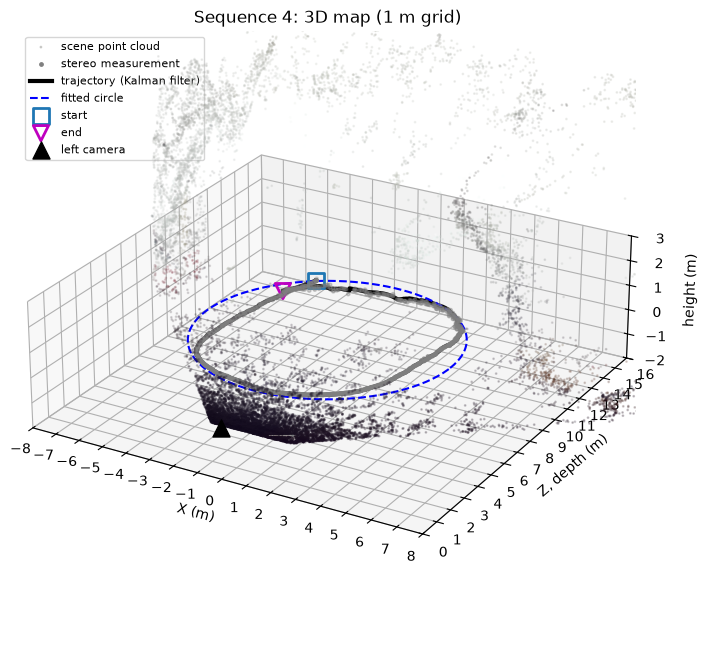

In [11]:
# %matplotlib qt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import MultipleLocator

# --- Scene point cloud from the empty background pair, same StereoBM as Step 1 ---
disp0 = disparity(background, background_R)
pts0 = cv2.reprojectImageTo3D(disp0, Q) / 1000                       # metres
m0 = (disp0 > 0) & (pts0[..., 2] > 0.5) & (pts0[..., 2] < 16)        # valid, closer than 16 m
cloud = pts0[m0]
rgb = cv2.cvtColor(background, cv2.COLOR_BGR2RGB)[m0] / 255
sel = np.random.default_rng(0).choice(len(cloud), min(20000, len(cloud)), replace=False)

# --- 3D map: X (right), Z (depth), height = -Y (up) ---
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(cloud[sel, 0], cloud[sel, 2], -cloud[sel, 1], c=rgb[sel], s=1, alpha=0.5, label="scene point cloud")
ax.scatter(xyz[:, 0], xyz[:, 2], -xyz[:, 1], c="grey", s=6, label="stereo measurement")
ax.plot(kf_xyz[:, 0], kf_xyz[:, 2], -kf_xyz[:, 1], "k-", lw=3, label="trajectory (Kalman filter)")

# fitted circle from Step 5b, drawn at the robot's mean height
y_mean = np.nanmean(kf_xyz[good, 1])
ax.plot(cx + rad * np.cos(t), cz + rad * np.sin(t), -y_mean * np.ones_like(t), "b--", lw=1.5, label="fitted circle")

valid = np.where(~np.isnan(kf_xyz[:, 0]))[0]
i0, i1 = valid[0], valid[-1]
ax.scatter(*kf_xyz[i0, [0, 2]], -kf_xyz[i0, 1], marker="s", s=120, facecolors="none", edgecolors="tab:blue", linewidths=2, label="start")
ax.scatter(*kf_xyz[i1, [0, 2]], -kf_xyz[i1, 1], marker="v", s=120, facecolors="none", edgecolors="m", linewidths=2, label="end")
ax.scatter(0, 0, 0, marker="^", s=150, c="black", label="left camera")

# 1 m x 1 m grid
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_locator(MultipleLocator(1.0))
ax.set_xlim(-8, 8); ax.set_ylim(0, 16); ax.set_zlim(-2, 3)
ax.set_box_aspect((16, 16, 5))                                       # equal scale on all axes
ax.set_xlabel("X (m)"); ax.set_ylabel("Z, depth (m)"); ax.set_zlabel("height (m)")
ax.set_title("Sequence 4: 3D map (1 m grid)")
ax.view_init(elev=25, azim=-60)
ax.legend(loc="upper left", fontsize=8)
plt.show()